In [1]:
# import library
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# load data
df = pd.read_csv('dataset_clean.csv')

# lihat 10 baris pertama data
df.head()

,nama_produk,varian_warna,hex_code,harga,deskripsi,link_produk
0,Wardah Colorfit Ultralight Matte Lipstick Kore...,09 Romantic Namsan,#A63E59,49900,"Lipstik berwarna Mauve pink, nude pink dengan ...",https://www.wardahbeauty.com/id/product/make-u...
1,Wardah Colorfit Ultralight Matte Lipstick Kore...,10 Stunning Seoul,#B33E2C,49900,Lipstik berwarna Merah dengan undertone oranye...,https://www.wardahbeauty.com/id/product/make-u...
2,Wardah Colorfit Ultralight Matte Lipstick Kore...,11 Sunkissed Jeju,#A23B4A,49900,Lipstik berwarna Cokelat medium dengan sentuha...,https://www.wardahbeauty.com/id/product/make-u...
3,Wardah Colorfit Ultralight Matte Lipstick Kore...,12 Autumn Nami,#9C3027,49900,Lipstik berwarna Merah bata atau terracotta de...,https://www.wardahbeauty.com/id/product/make-u...
4,Wardah Colorfit Ultralight Matte Lipstick Kore...,13 Upbeat Hongdae,#A51D3D,49900,Lipstik berwarna Merah berry dengan undertone ...,https://www.wardahbeauty.com/id/product/make-u...


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226 entries, 0 to 225
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   nama_produk   226 non-null    object
 1   varian_warna  226 non-null    object
 2   hex_code      226 non-null    object
 3   harga         226 non-null    int64 
 4   deskripsi     226 non-null    object
 5   link_produk   226 non-null    object
dtypes: int64(1), object(5)
memory usage: 10.7+ KB


In [4]:
# kolom baru nama brand
df['brand'] = df['nama_produk'].str.split().str[0]

df['brand'] = df['brand'].replace('MAKE', 'MAKE OVER')

# Chart 1

C:\Users\ASUS\AppData\Local\Temp\ipykernel_17188\585043271.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=brand_counts.index, y=brand_counts.values, palette='viridis')


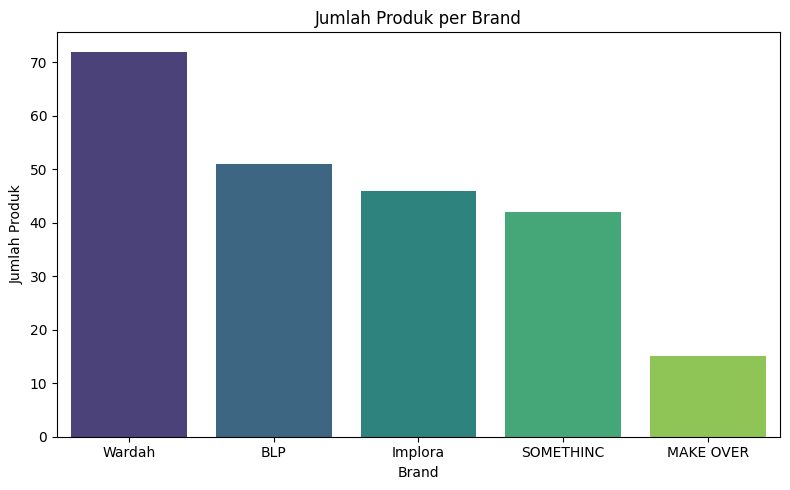

In [5]:
# Hitung frekuensi tiap brand
brand_counts = df['brand'].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=brand_counts.index, y=brand_counts.values, palette='viridis')

plt.title('Jumlah Produk per Brand')
plt.xlabel('Brand')
plt.ylabel('Jumlah Produk')
plt.tight_layout()
plt.show()

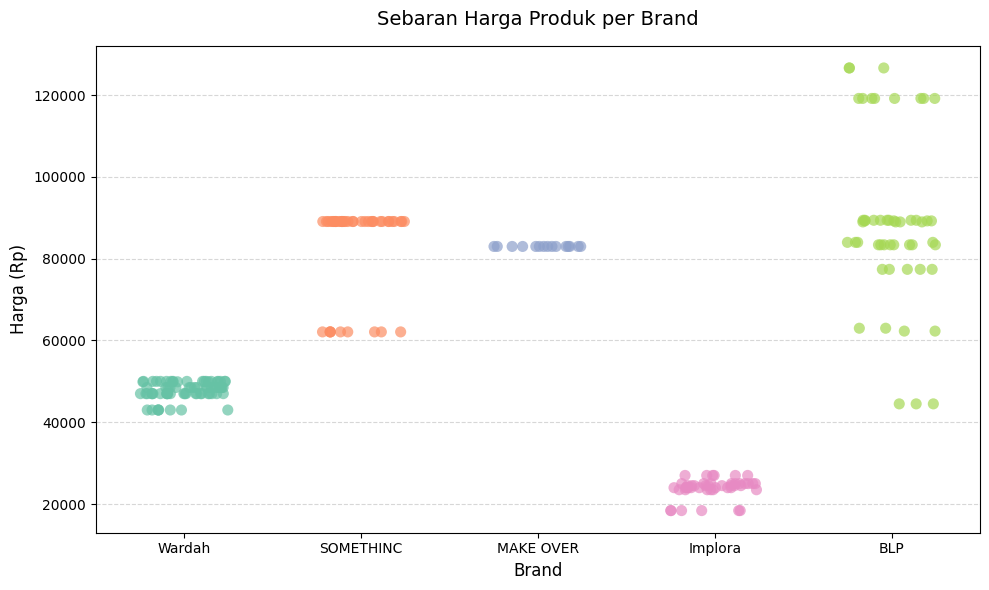

In [6]:
plt.figure(figsize=(10, 6))
sns.stripplot(
    data=df,
    x='brand',
    y='harga',
    hue='brand',
    jitter=0.25,
    size=8,
    alpha=0.7,
    palette='Set2',
)

plt.title('Sebaran Harga Produk per Brand', fontsize=14, pad=15)
plt.xlabel('Brand', fontsize=12)
plt.ylabel('Harga (Rp)', fontsize=12)
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

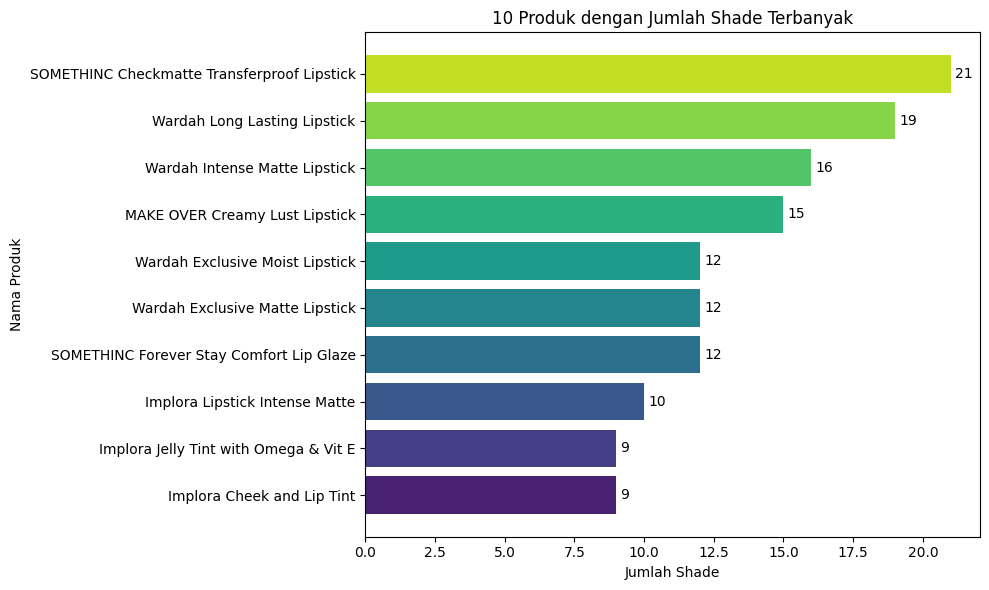

In [7]:
shade_counts = (
    df.groupby('nama_produk')['varian_warna']
    .nunique()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    shade_counts.index,
    shade_counts.values,
    color=sns.color_palette('viridis', len(shade_counts))
)

plt.bar_label(bars, padding=3)

plt.title('10 Produk dengan Jumlah Shade Terbanyak')
plt.xlabel('Jumlah Shade')
plt.ylabel('Nama Produk')
plt.tight_layout()
plt.show()

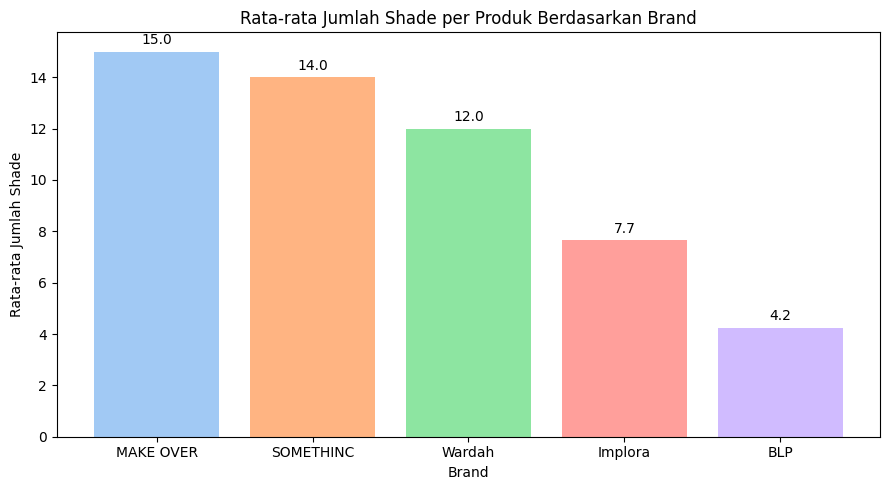

In [8]:
# hitung jumlah shade untuk setiap produk
shade_per_product = (
    df.groupby(['brand', 'nama_produk'])['varian_warna']
    .nunique()
    .reset_index(name='jumlah_shade')
)

# hitung rata-rata jumlah shade per brand
avg_shade = (
    shade_per_product.groupby('brand')['jumlah_shade']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    avg_shade.index,
    avg_shade.values,
    color=sns.color_palette('pastel', len(avg_shade))
)

plt.bar_label(bars, fmt='%.1f', padding=3)

plt.title('Rata-rata Jumlah Shade per Produk Berdasarkan Brand')
plt.xlabel('Brand')
plt.ylabel('Rata-rata Jumlah Shade')
plt.tight_layout()
plt.show()

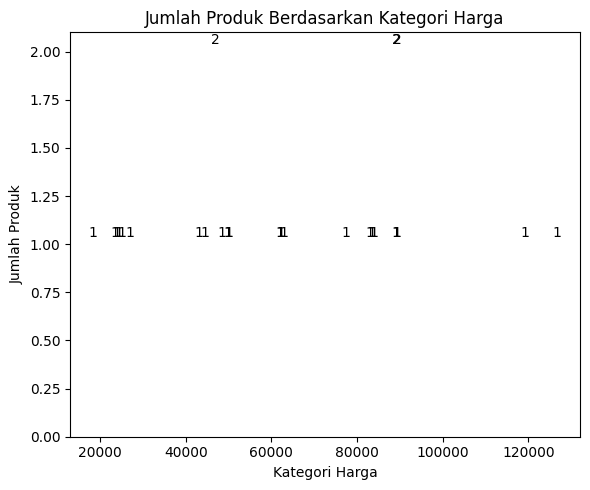

In [9]:
# ambil satu baris untuk setiap produk unik
product_price = df.drop_duplicates(subset='nama_produk').copy()

# kategorisasi harga
product_price['kategori_harga'] = pd.cut(
    product_price['harga'],
    bins=[0, 50000, 100000, float('inf')],
    labels=[
        '< Rp50.000',
        'Rp50.000 - < Rp100.000',
        '≥ Rp100.000'
    ],
    right=False
)

# hitung jumlah produk pada setiap kategori
price_counts = (
    product_price['harga']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(6, 5))

bars = plt.bar(
    price_counts.index,
    price_counts.values,
    color=sns.color_palette('Set2', len(price_counts))
)

plt.bar_label(bars, padding=3)

plt.title('Jumlah Produk Berdasarkan Kategori Harga')
plt.xlabel('Kategori Harga')
plt.ylabel('Jumlah Produk')
plt.tight_layout()
plt.show()